In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

In [ ]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

In [ ]:
train.head()

In [ ]:
test.head()

In [ ]:
train.info()

In [ ]:
test.info()

## Visualization

In [ ]:
sns.countplot(x=train['Survived'], hue=train['Sex'])
plt.xlabel('Survived')
plt.ylabel('Count')
plt.title('Survival Count by Sex')
plt.show()

sns.countplot(x=train['Survived'], hue=train['Pclass'])
plt.xlabel('Survived')
plt.ylabel('Count')
plt.title('Survival Count by Pclassz')
plt.show()

sns.countplot(x=train['Sex'], hue=train['Pclass'])
plt.xlabel('Sex')
plt.ylabel('Count')
plt.title('Gender of people depending on the class')
plt.show()

In [ ]:
sns.histplot(x=train['Age']);
plt.title("Age");

<font size="3">Correlation between variables.</font>

In [ ]:
sns.heatmap(train.corr());

## Data preparation

In [ ]:
def DropFeatures(X):
    return X.drop(['PassengerId','Survived','Name','Ticket','Cabin', 'N', "Sex", "Embarked"], axis=1, errors="ignore")

def FeatureEncoder(X):
    encoder = OneHotEncoder()
    matrix = encoder.fit_transform(X[['Embarked']]).toarray()

    column_names = ["C", "S", "Q", "N"]

    for i in range(len(matrix.T)):
        X[column_names[i]] = matrix.T[i]

    matrix = encoder.fit_transform(X[['Sex']]).toarray()  
    column_names = ["Female", "Male"]

    for i in range(len(matrix.T)):
        X[column_names[i]] = matrix.T[i]

    return X

In [ ]:
train_data = FeatureEncoder(train)
X = DropFeatures(train_data)
y = train['Survived']

In [ ]:
X.info()

In [ ]:
X['Age'] = X['Age'].fillna(X.Age.median())

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
y_scaled = y.to_numpy()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=.3, random_state=17) 

## Model Training

In [ ]:
clf = RandomForestClassifier(random_state=17)

params = {
    'n_estimators':[10, 100, 200, 500, 600],
    'max_depth':[None, 5, 10],
    "min_samples_split": [2, 3 ,4],
}

search = GridSearchCV(clf, params, cv=3, scoring='accuracy')
search.fit(X_train, y_train)

In [ ]:
best_model = search.best_estimator_

In [ ]:
best_model.score(X_test, y_test)

## Prediction

In [ ]:
test_data = FeatureEncoder(test)
X_test_set = DropFeatures(test_data)

In [ ]:
X_test_set.info()

In [ ]:
X_test_set.head()

In [ ]:
X_test_set['Age'] = X_test_set['Age'].fillna(X_test_set.Age.median())
X_test_set['Fare'] = X_test_set['Fare'].fillna(X_test_set.Fare.mean())

In [ ]:
scaler = StandardScaler()
X_data_final_test = scaler.fit_transform(X_test_set)

In [ ]:
pred = best_model.predict(X_data_final_test)

In [ ]:
df_pred = pd.DataFrame(test['PassengerId'])
df_pred['Survived'] = pred 
df_pred.to_csv("predictions/Titanic prediction.csv", index=False)

## Result

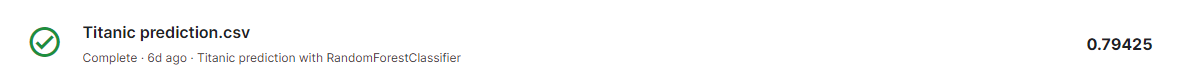

<font size="4">I claimed the 679th spot out of 14872.</font>

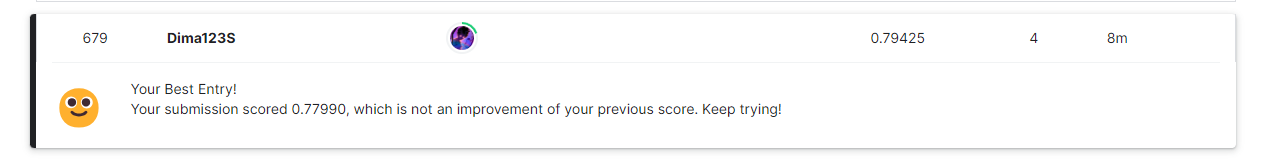